In [1]:
pip install pyclustering

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 28.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pyclustering: filename=pyclustering-0.10.1.2-py3-none-any.whl size=2395100 sha256=7cfe60c8f77c3b36eb8eebcb44fb34c1dc27b49df9a0ccd8140aee696ceda463
  Stored in directory: /root/.cache/pip/wheels/68/29/b4/131bd7deec3663cc311ab9aa64d6517c3e3ec24bcadfc32f74
Successfully built pyclustering
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import Library

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.decomposition import PCA

from pyclustering.cluster.kmedoids import kmedoids
from pyclustering.cluster.silhouette import silhouette
from sklearn.metrics import pairwise_distances

from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

import warnings
warnings.filterwarnings('ignore')

# **Business Understanding**

**Latar Belakang**

Korean Drama (K-Drama) telah menjadi fenomena global yang berkembang pesat seiring dengan meningkatnya popularitas Korean Wave (Hallyu). Berbagai platform streaming seperti Netflix, Viki, dan WeTV menyediakan ratusan hingga ribuan judul drama dengan karakteristik yang beragam.

Namun, banyaknya pilihan tersebut menimbulkan tantangan bagi penonton dalam menentukan drama yang ingin ditonton. Selain itu, tidak semua drama memiliki tingkat popularitas yang sama, sehingga terdapat variasi dalam jumlah penonton, peringkat, dan tingkat ketertarikan terhadap suatu drama.

Di sisi lain, platform streaming membutuhkan pemahaman terhadap pola popularitas konten untuk:
* meningkatkan pengalaman pengguna
* menyusun strategi rekomendasi yang lebih efektif

Oleh karena itu, diperlukan pendekatan berbasis data untuk mengelompokkan drama berdasarkan tingkat popularitas dan performanya.

**Business Goals**

Mengelompokkan drama Korea berdasarkan tingkat popularitas dan performa menggunakan teknik clustering, sehingga dapat:

* Membantu platform streaming dalam memahami segmentasi popularitas drama
* Mendukung sistem rekomendasi dalam menyarankan drama berdasarkan tingkat popularitas (misalnya: populer, sedang, atau niche)
* Memudahkan penonton dalam menemukan drama sesuai preferensi, baik yang populer maupun yang kurang dikenal

**Problem Statement**

Bagaimana cara mengelompokkan drama Korea ke dalam beberapa cluster dengan menggunakan algoritma **K-Medoids** berdasarkan tingkat popularitas dan performanya, sehingga setiap cluster merepresentasikan kategori tertentu  yang dapat digunakan untuk mendukung sistem rekomendasi?

# **Data Understanding**

In [3]:
kdramalist = pd.read_csv('/kaggle/input/datasets/iphigeniebera/korean-drama-list-about-740-unique-dramas/kdramalist.csv')
kdramalist

,drama_name,Genres,Tags,Episodes,start airing,end airing,Aired On,Original Network,Duration,score,scored by,Ranked,Popularity,Content Rating,Watchers,actors,platforms,imdb_rating,imdb_user_count,imdb_description
0,100 Days My Prince,"['historical', 'comedy', 'romance', 'drama']","['amnesia', 'hidden identity', 'marriage of co...",16,10-Sep-18,30-Oct-18,"['tuesday', 'monday']",['tvN'],75.0,8.3,21274.0,554,136,15+ - Teens 15 or older,"45,852","['Doh Kyung Soo', 'Nam Ji Hyun', 'Kim Seon Ho'...","['WeTV', 'Netflix', 'K-DRAMA', 'Apple TV', 'Vi...",7.7,"2,188","Upon losing his memory, a crown prince encount..."
1,12 Signs of Love,"['comedy', 'romance', 'life']",['writer female lead '],16,15-Feb-12,5-Apr-12,"['wednesday', 'thursday']",['tvN'],65.0,7.1,893.0,5506,3327,Not Yet Rated,"2,543","['Ohn Joo Wan', 'Yoon Jin Seo', 'Lee Yong Woo'...",[],NaN,NaN,NaN
2,12 Years Promise,"['food', 'romance', 'drama', 'family']","['unexpected pregnancy', 'miscarriage', 'teena...",26,22-Mar-14,29-Jun-14,"['saturday', 'sunday']",['jTBC'],70.0,7.2,2716.0,5395,1783,15+ - Teens 15 or older,"5,435","['Lee So Yeon', 'Namkoong Min', 'Lee Tae Im', ...",['Viki'],7.3,181,A pregnant teen is forced by her family to lea...
3,18 Again,"['romance', 'life', 'drama', 'fantasy']","['second chance', 'first love', 'father-son re...",16,21-Sep-20,10-Nov-20,"['monday', 'tuesday']",['jTBC'],70.0,8.7,21409.0,105,125,15+ - Teens 15 or older,"47,527","['Kim Ha Neul', 'Yoon Sang Hyun', 'Lee Do Hyun...",['WeTV'],8.2,"1,847",A 37-year-old man on the verge of being divorc...
4,365: Repeat the Year,"['thriller', 'mystery', 'drama', 'fantasy']","['strong female lead', 'time travel', 'nice ma...",24,23-Mar-20,28-Apr-20,"['monday', 'tuesday']",['MBC'],35.0,8.6,7598.0,250,438,15+ - Teens 15 or older,"20,963","['Lee Joon Hyuk', 'Nam Ji Hyun', 'Kim Jee Soo'...",['Viki'],8.0,656,A story where ten people get the chance to go ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1273,Your Neighbor's Wife,"['mystery', 'comedy', 'romance', 'family']","['married female lead', 'housewife female lead...",22,14-Oct-13,24-Dec-13,"['monday', 'tuesday']",['jTBC'],60.0,7.3,65.0,70712,9624,15+ - Teens 15 or older,454,"['Shin Eun Kyung', 'Yeom Jung Ah', 'Jung Joon ...",['Viki'],7.0,7,Two couples who live in the same apartment are...
1274,Youth,"['music', 'life', 'youth', 'drama']","['time travel', 'death of a mother', 'secret',...",0,2022,?,NaN,NaN,NaN,NaN,NaN,31736,3664,15+ - Teens 15 or older,"2,212","['Seo Ji Hoon', 'Noh Jong Hyun', 'Ahn Ji Ho', ...",[],NaN,NaN,NaN
1275,Youth of May,"['historical', 'romance', 'youth', 'drama']","['1980s', 'rich man/poor woman', 'gwangju upri...",12,3-May-21,8-Jun-21,"['monday', 'tuesday']",['KBS2'],70.0,8.8,12576.0,81,211,15+ - Teens 15 or older,"35,183","['Lee Do Hyun', 'Go Min Si', 'Lee Sang Yi', 'G...","['Prime Video', 'Viki', 'Netflix']",8.4,"1,240","Set in 1980s during the Gwangju Uprising, Yout..."
1276,Yumi's Cells,"['psychological', 'comedy', 'romance', 'drama']","['slice of life', 'adapted from a webtoon', 'f...",14,17-Sep-21,30-Oct-21,"['friday', 'saturday']",['tvN'],70.0,8.5,13469.0,365,256,13+ - Teens 13 or older,"30,832","['Kim Go Eun', 'Ahn Bo Hyun', 'Park Ji Hyun', ...","['TVING', 'Viki']",8.2,"2,030",The story of an ordinary office worker named Y...


In [4]:
kdramalist.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1278 entries, 0 to 1277
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   drama_name        1278 non-null   object 
 1   Genres            1277 non-null   object 
 2   Tags              1278 non-null   object 
 3   Episodes          1278 non-null   int64  
 4   start airing      1255 non-null   object 
 5   end airing        1221 non-null   object 
 6   Aired On          1222 non-null   object 
 7   Original Network  1250 non-null   object 
 8   Duration          1230 non-null   float64
 9   score             1239 non-null   float64
 10  scored by         1239 non-null   float64
 11  Ranked            1278 non-null   int64  
 12  Popularity        1278 non-null   int64  
 13  Content Rating    1278 non-null   object 
 14  Watchers          1278 non-null   object 
 15  actors            1278 non-null   object 
 16  platforms         1278 non-null   object 


In [5]:
cols = ['score', 'Watchers', 'Popularity', 'Ranked']

kdramalist[cols].describe()

,score,Popularity,Ranked
count,1239.000000,1278.000000,1278.000000
mean,7.698951,10206.134585,20229.890454
std,0.597510,26061.476796,30401.464575
min,4.000000,1.000000,3.000000
25%,7.300000,508.500000,1296.250000
50%,7.700000,1715.000000,3705.500000
75%,8.100000,5248.000000,32058.750000
max,10.000000,99999.000000,99999.000000


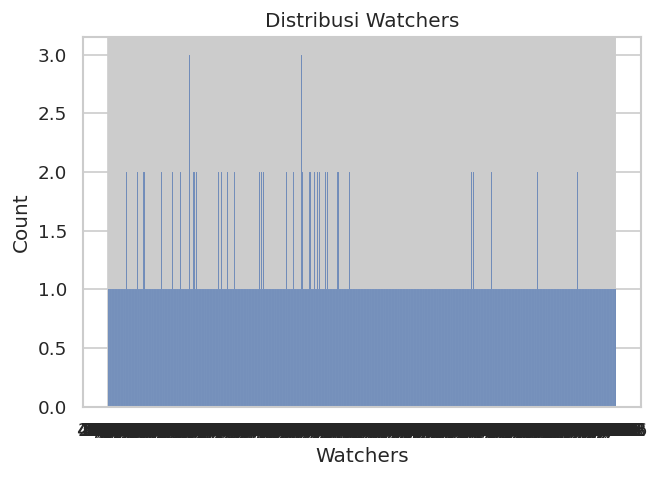

In [6]:
plt.figure(figsize=(6,4))
sns.histplot(kdramalist['Watchers'], bins=30)
plt.title("Distribusi Watchers")
plt.show()

Text(0.5, 1.0, 'Distribusi Watchers (Log)')

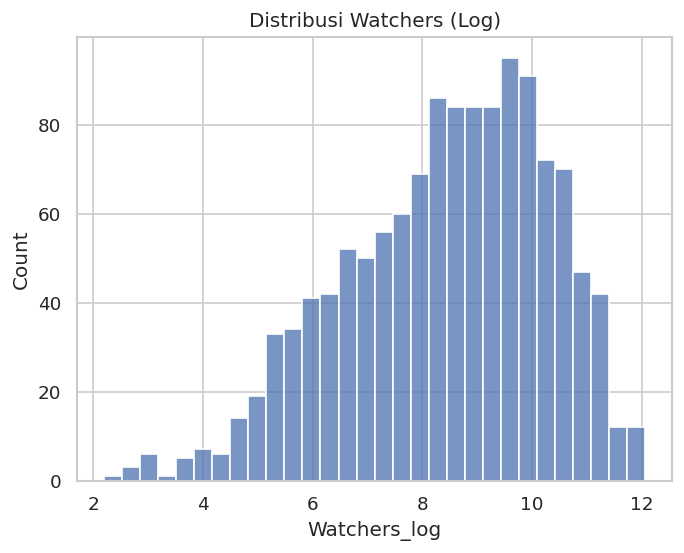

In [7]:
kdramalist['Watchers'] = pd.to_numeric(
    kdramalist['Watchers'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

kdramalist['Watchers_log'] = np.log1p(kdramalist['Watchers'])

sns.histplot(kdramalist['Watchers_log'], bins=30)
plt.title("Distribusi Watchers (Log)")

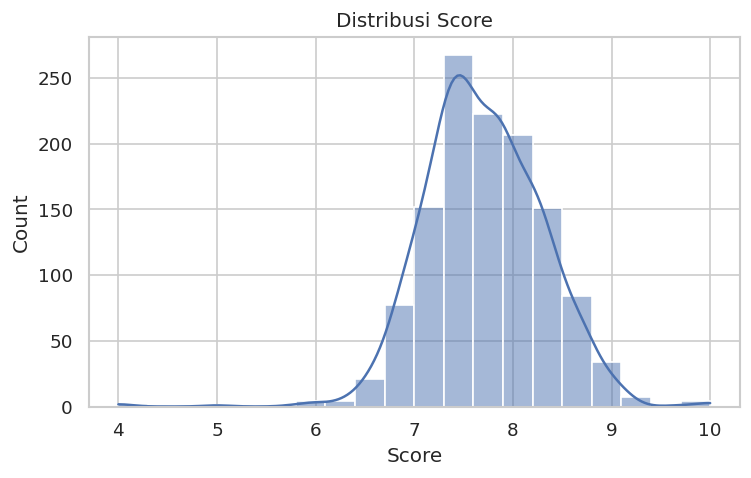

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(kdramalist['score'], bins=20, kde=True)
plt.title('Distribusi Score')
plt.xlabel('Score')
plt.ylabel('Count')
plt.show()

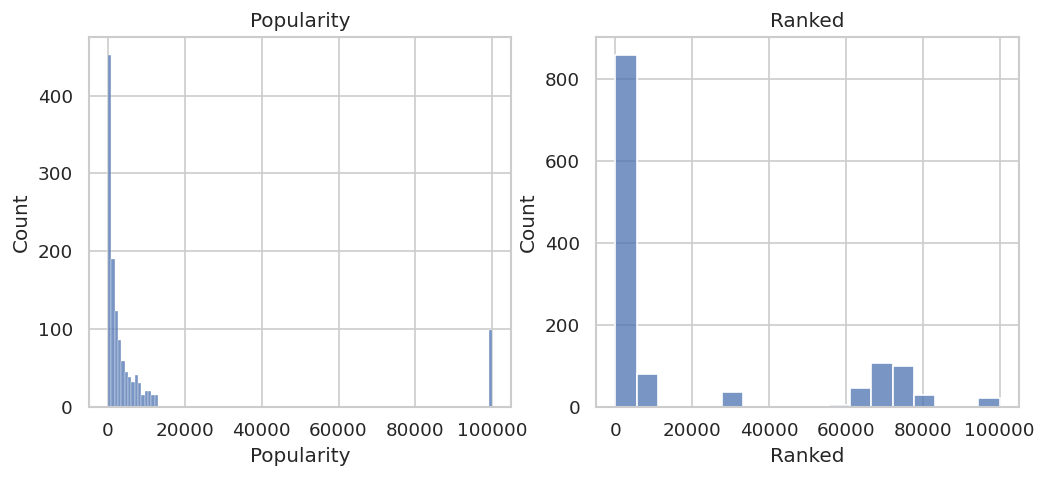

In [9]:
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.histplot(kdramalist['Popularity'], ax=ax[0])
ax[0].set_title("Popularity")

sns.histplot(kdramalist['Ranked'], ax=ax[1])
ax[1].set_title("Ranked")

plt.show()

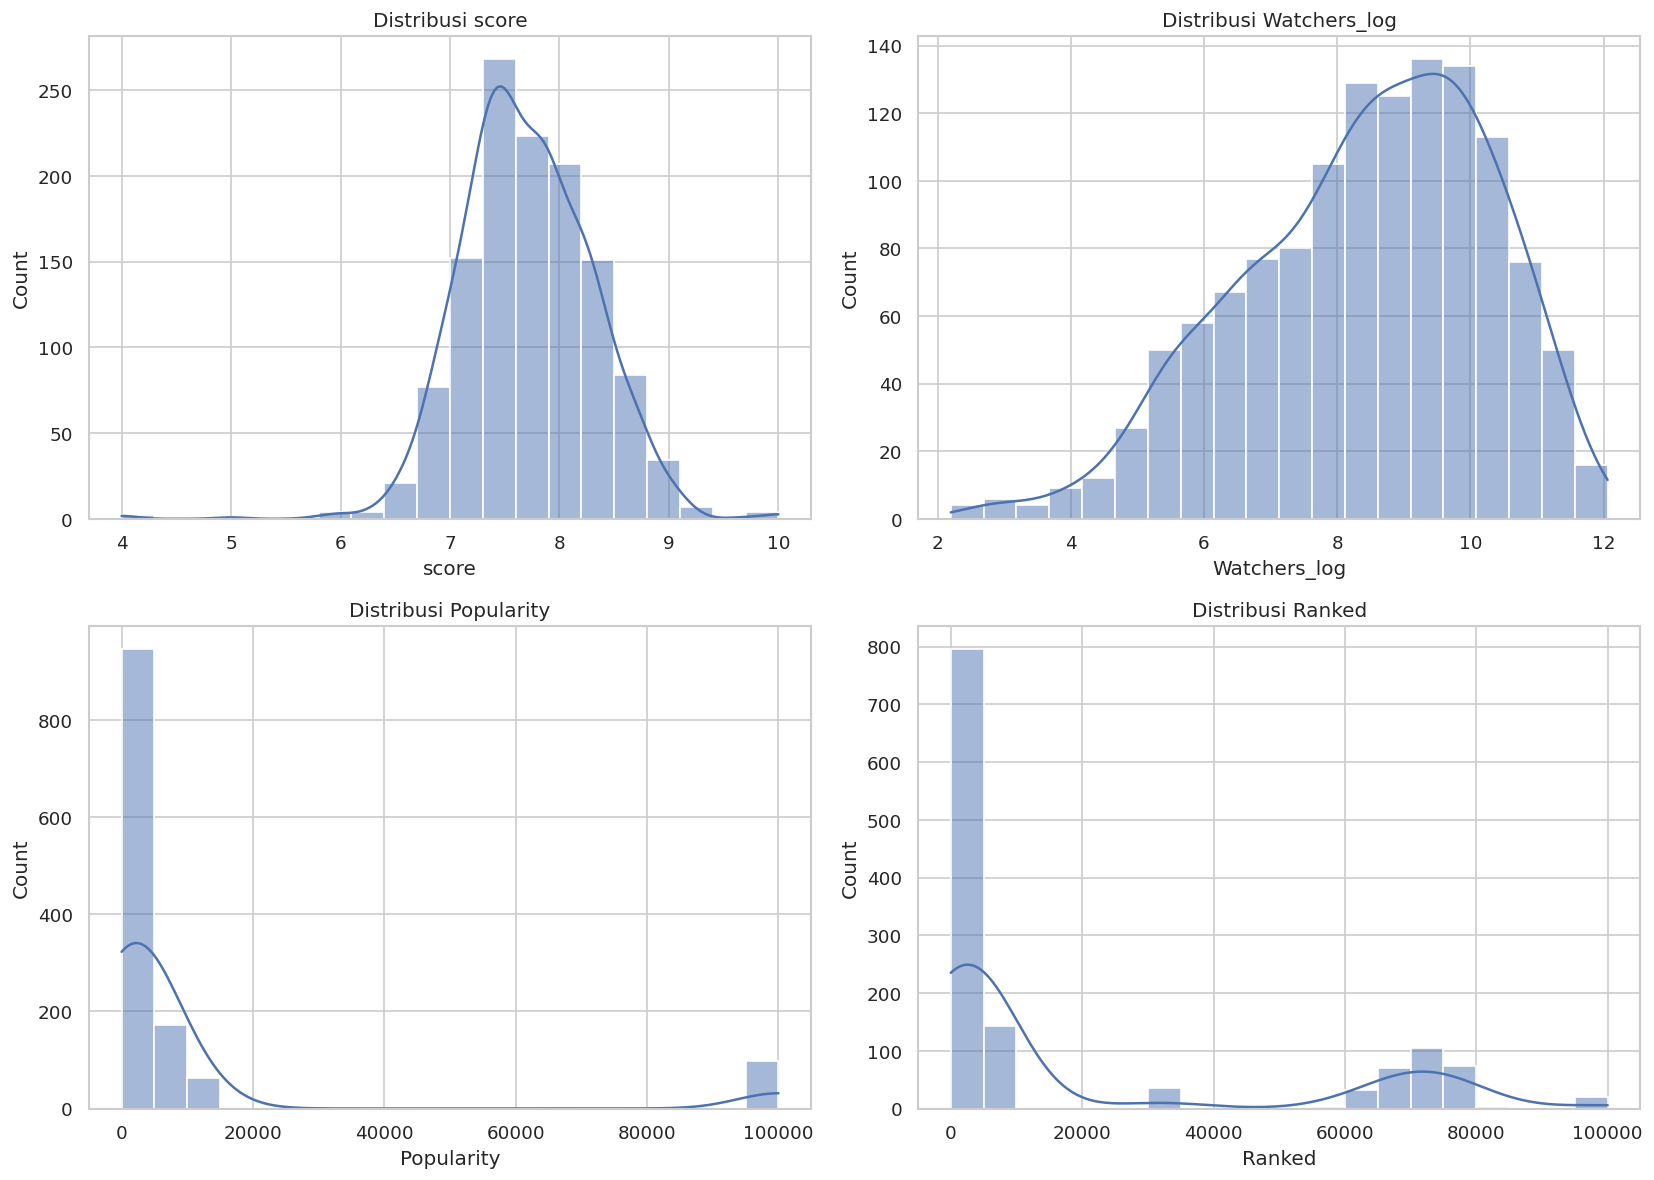

In [10]:
features = ['score', 'Watchers_log', 'Popularity', 'Ranked']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(kdramalist[col], bins=20, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

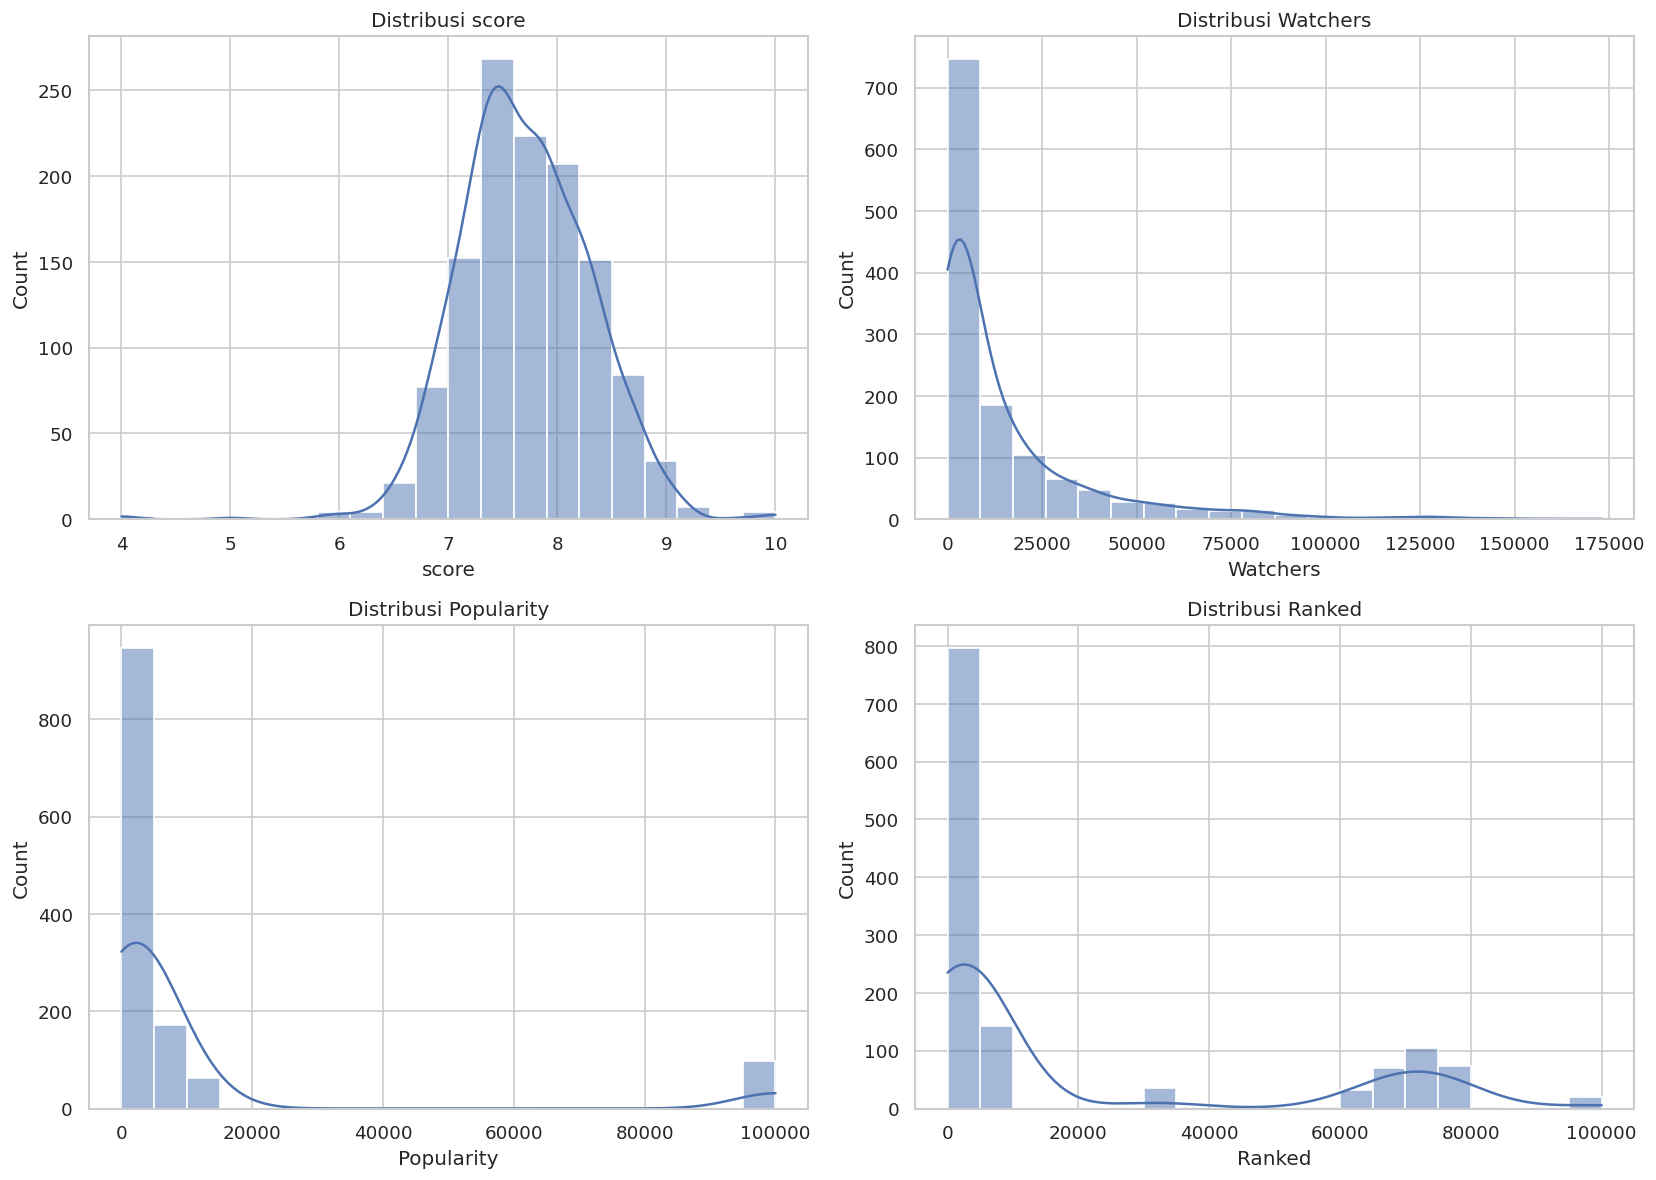

In [11]:
features = ['score', 'Watchers', 'Popularity', 'Ranked']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(kdramalist[col], bins=20, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

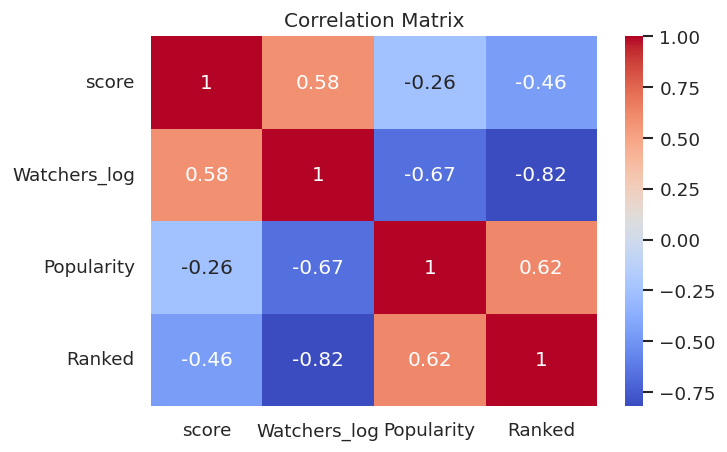

In [12]:
plt.figure(figsize=(6,4))
sns.heatmap(
    kdramalist[['score', 'Watchers_log', 'Popularity', 'Ranked']].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Matrix")
plt.show()

# **Data Preparation**

In [13]:
df = kdramalist[['drama_name', 'score', 'Watchers', 'Popularity', 'Ranked']].copy()

print("Shape:", df.shape)
df

Shape: (1278, 5)


,drama_name,score,Watchers,Popularity,Ranked
0,100 Days My Prince,8.3,45852,136,554
1,12 Signs of Love,7.1,2543,3327,5506
2,12 Years Promise,7.2,5435,1783,5395
3,18 Again,8.7,47527,125,105
4,365: Repeat the Year,8.6,20963,438,250
...,...,...,...,...,...
1273,Your Neighbor's Wife,7.3,454,9624,70712
1274,Youth,NaN,2212,3664,31736
1275,Youth of May,8.8,35183,211,81
1276,Yumi's Cells,8.5,30832,256,365


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1278 entries, 0 to 1277
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   drama_name  1278 non-null   object 
 1   score       1239 non-null   float64
 2   Watchers    1278 non-null   int64  
 3   Popularity  1278 non-null   int64  
 4   Ranked      1278 non-null   int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 50.1+ KB


In [15]:
df['Watchers'] = pd.to_numeric(
    df['Watchers'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

print("Setelah cleaning Watchers:")
df

Setelah cleaning Watchers:


,drama_name,score,Watchers,Popularity,Ranked
0,100 Days My Prince,8.3,45852,136,554
1,12 Signs of Love,7.1,2543,3327,5506
2,12 Years Promise,7.2,5435,1783,5395
3,18 Again,8.7,47527,125,105
4,365: Repeat the Year,8.6,20963,438,250
...,...,...,...,...,...
1273,Your Neighbor's Wife,7.3,454,9624,70712
1274,Youth,NaN,2212,3664,31736
1275,Youth of May,8.8,35183,211,81
1276,Yumi's Cells,8.5,30832,256,365


In [16]:
cols = ['score', 'Popularity', 'Ranked']

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Setelah convert numeric:")
df

Setelah convert numeric:


,drama_name,score,Watchers,Popularity,Ranked
0,100 Days My Prince,8.3,45852,136,554
1,12 Signs of Love,7.1,2543,3327,5506
2,12 Years Promise,7.2,5435,1783,5395
3,18 Again,8.7,47527,125,105
4,365: Repeat the Year,8.6,20963,438,250
...,...,...,...,...,...
1273,Your Neighbor's Wife,7.3,454,9624,70712
1274,Youth,NaN,2212,3664,31736
1275,Youth of May,8.8,35183,211,81
1276,Yumi's Cells,8.5,30832,256,365


In [17]:
print("Missing values:")
df.isnull().sum()

Missing values:


drama_name     0
score         39
Watchers       0
Popularity     0
Ranked         0
dtype: int64

In [18]:
df = df.dropna()

print("Setelah drop NA:", df.shape)
df

Setelah drop NA: (1239, 5)


,drama_name,score,Watchers,Popularity,Ranked
0,100 Days My Prince,8.3,45852,136,554
1,12 Signs of Love,7.1,2543,3327,5506
2,12 Years Promise,7.2,5435,1783,5395
3,18 Again,8.7,47527,125,105
4,365: Repeat the Year,8.6,20963,438,250
...,...,...,...,...,...
1272,Your Lady,7.2,419,10045,73122
1273,Your Neighbor's Wife,7.3,454,9624,70712
1275,Youth of May,8.8,35183,211,81
1276,Yumi's Cells,8.5,30832,256,365


In [19]:
df['Watchers_log'] = np.log1p(df['Watchers'])

print("Setelah log transform:")
df[['Watchers', 'Watchers_log']]

Setelah log transform:


,Watchers,Watchers_log
0,45852,10.733196
1,2543,7.841493
2,5435,8.600799
3,47527,10.769074
4,20963,9.950562
...,...,...
1272,419,6.040255
1273,454,6.120297
1275,35183,10.468347
1276,30832,10.336341


In [20]:
df_model = df[['score', 'Watchers_log', 'Popularity', 'Ranked']]

print("Data model:")
df_model

Data model:


,score,Watchers_log,Popularity,Ranked
0,8.3,10.733196,136,554
1,7.1,7.841493,3327,5506
2,7.2,8.600799,1783,5395
3,8.7,10.769074,125,105
4,8.6,9.950562,438,250
...,...,...,...,...
1272,7.2,6.040255,10045,73122
1273,7.3,6.120297,9624,70712
1275,8.8,10.468347,211,81
1276,8.5,10.336341,256,365


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model)

df_scaled = pd.DataFrame(X_scaled, columns=df_model.columns)

print("Setelah scaling:")
df_scaled

Setelah scaling:


,score,Watchers_log,Popularity,Ranked
0,1.006329,1.222111,-0.382810,-0.626609
1,-1.002816,-0.339370,-0.259804,-0.464035
2,-0.835387,0.070645,-0.319321,-0.467679
3,1.676044,1.241485,-0.383234,-0.641350
4,1.508616,0.799499,-0.371168,-0.636590
...,...,...,...,...
1234,-0.835387,-1.312015,-0.000839,1.755804
1235,-0.667958,-1.268793,-0.017068,1.676683
1236,1.843473,1.079096,-0.379919,-0.642138
1237,1.341187,1.007815,-0.378184,-0.632814


# **Modelling (K-Medoids)**

In [22]:
X = X_scaled

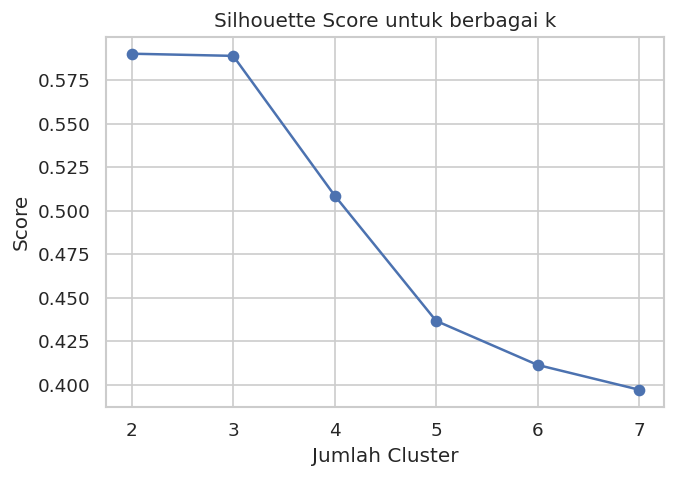

{2: np.float64(0.5901737300630724), 3: np.float64(0.5889255927095571), 4: np.float64(0.5086962360012535), 5: np.float64(0.43671430899596164), 6: np.float64(0.4113949929035484), 7: np.float64(0.39716810510683037)}


In [23]:
from sklearn.metrics import silhouette_score
import numpy as np

sil_scores = []
range_k = range(2, 8)

for k in range_k:
    # medoid awal pakai indeks awal biar konsisten
    initial_medoids = list(range(k))
    
    kmedoids_instance = kmedoids(X, initial_medoids)
    kmedoids_instance.process()
    
    clusters = kmedoids_instance.get_clusters()
    
    # ubah ke label
    labels = np.zeros(len(X))
    for i, cluster in enumerate(clusters):
        for idx in cluster:
            labels[idx] = i
    
    score = silhouette_score(X, labels)
    sil_scores.append(score)

# plot
plt.figure(figsize=(6,4))
plt.plot(range_k, sil_scores, marker='o')
plt.title("Silhouette Score untuk berbagai k")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Score")
plt.show()

print(dict(zip(range_k, sil_scores)))

In [24]:
k_best = 3

In [25]:
k = k_best

initial_medoids = list(range(k))

kmedoids_instance = kmedoids(X, initial_medoids)
kmedoids_instance.process()

clusters = kmedoids_instance.get_clusters()
medoids = kmedoids_instance.get_medoids()

In [26]:
labels = np.zeros(len(X))

for i, cluster in enumerate(clusters):
    for idx in cluster:
        labels[idx] = i

In [27]:
df['cluster'] = labels

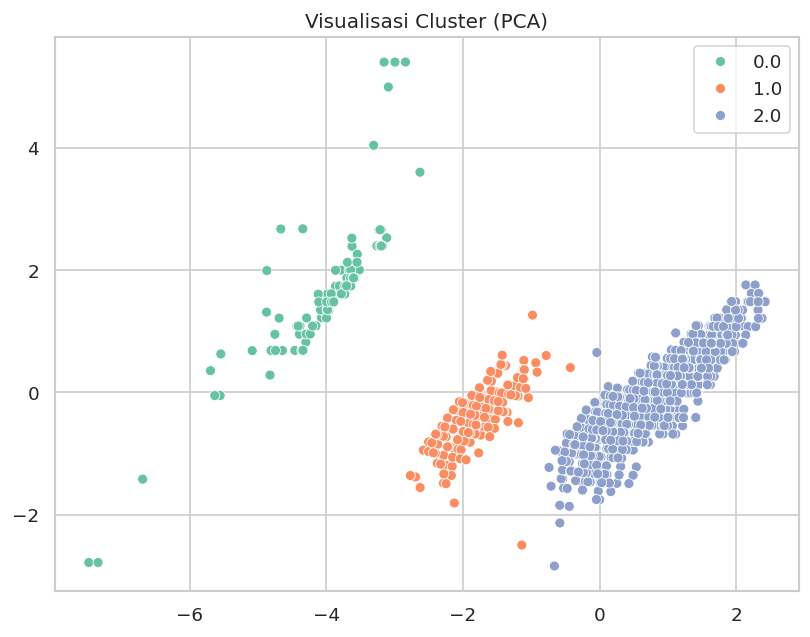

In [28]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels, palette='Set2')
plt.title("Visualisasi Cluster (PCA)")
plt.show()

# **Evaluasi**

In [29]:
final_score = silhouette_score(X, labels)
print("Silhouette Score:", final_score)

Silhouette Score: 0.5889255927095571


In [30]:
cluster_summary = df.groupby('cluster')[['score','Watchers_log','Popularity','Ranked']].mean()
cluster_summary

,score,Watchers_log,Popularity,Ranked
cluster,,,,
0.0,7.276596,4.672974,99999.000000,76429.936170
1.0,7.268932,6.430406,8359.135922,71166.179612
2.0,7.835570,9.297520,1438.601704,2651.603834


In [31]:
for c in sorted(df['cluster'].unique()):
    print(f"\n🎬 Cluster {c}")
    display(
        df[df['cluster'] == c][['drama_name','score','Watchers','Popularity','Ranked']]
    )


🎬 Cluster 0.0


,drama_name,score,Watchers,Popularity,Ranked
6,5th Republic,6.9,81,99999,76723
15,A Happy Woman,6.6,163,99999,79155
38,"Aeja's Older Sister, Minja",8.1,117,99999,61034
41,Age of Warriors,7.3,103,99999,70995
53,Ang Shim Jung,7.2,150,99999,73280
...,...,...,...,...,...
1252,Yeon Gaesomun,7.4,176,99999,69697
1253,Yeonnam-dong 539,7.3,211,99999,71868
1256,You and I,7.7,123,99999,64837
1261,You Are the Boss!,7.2,194,99999,72898



🎬 Cluster 1.0


,drama_name,score,Watchers,Popularity,Ranked
9,#Alive,7.4,1025,6080,68801
11,A Bird That Doesn't Sing,7.3,552,8632,70822
23,A Place in the Sun,7.4,1545,4617,70165
27,A Tale of Two Sisters,6.7,741,7344,78785
51,Amor Fati,7.3,446,9702,72047
...,...,...,...,...,...
1262,You Are the Only One,7.3,807,7015,71854
1263,You Are Too Much,6.8,1270,5282,77631
1268,You're Only Mine,7.1,302,11841,75001
1272,Your Lady,7.2,419,10045,73122



🎬 Cluster 2.0


,drama_name,score,Watchers,Popularity,Ranked
0,100 Days My Prince,8.3,45852,136,554
1,12 Signs of Love,7.1,2543,3327,5506
2,12 Years Promise,7.2,5435,1783,5395
3,18 Again,8.7,47527,125,105
4,365: Repeat the Year,8.6,20963,438,250
...,...,...,...,...,...
1270,Your Honor,8.1,11620,896,1267
1271,Your House Helper,7.9,9200,1105,2090
1275,Youth of May,8.8,35183,211,81
1276,Yumi's Cells,8.5,30832,256,365


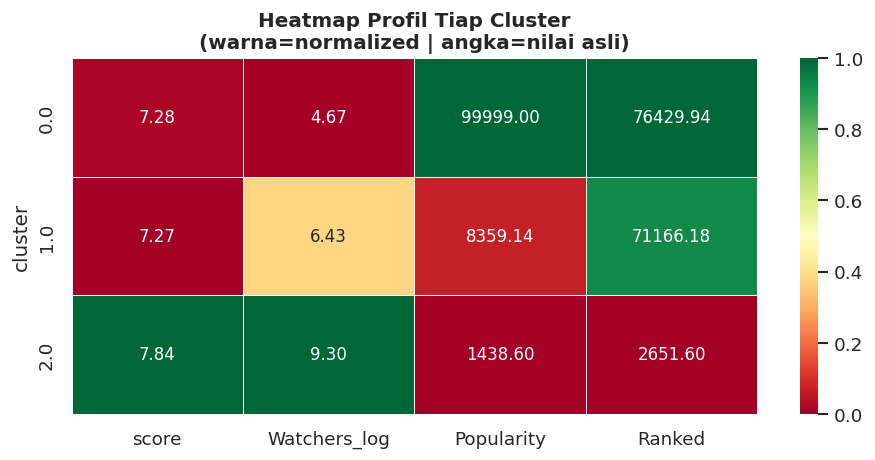

In [32]:
# Heatmap Profil Cluster

fig, ax = plt.subplots(figsize=(8, 4))

# Normalisasi untuk warna yang adil
profil_norm = (cluster_summary - cluster_summary.min()) / \
              (cluster_summary.max() - cluster_summary.min())

sns.heatmap(
    profil_norm,
    annot=cluster_summary.round(2).values,
    fmt='.2f',
    cmap='RdYlGn',
    linewidths=0.5,
    ax=ax,
    annot_kws={'size': 10}
)

ax.set_title('Heatmap Profil Tiap Cluster\n(warna=normalized | angka=nilai asli)',
             fontweight='bold')
plt.tight_layout()
plt.show()

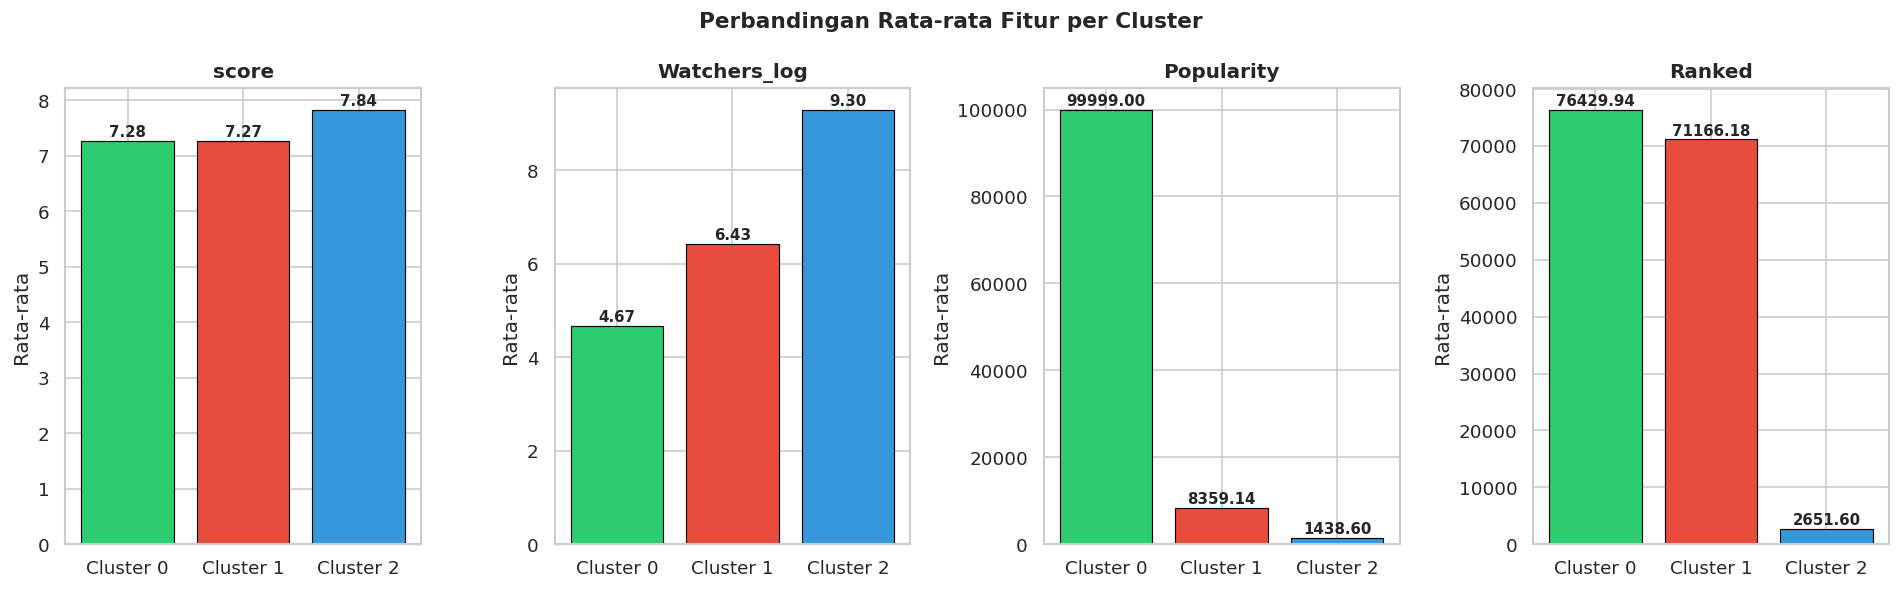

In [33]:
# Bar Chart

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle('Perbandingan Rata-rata Fitur per Cluster', fontweight='bold', fontsize=13)

fitur_plot = ['score', 'Watchers_log', 'Popularity', 'Ranked']
colors = ['#2ECC71', '#E74C3C', '#3498DB']

for i, col in enumerate(fitur_plot):
    vals = cluster_summary[col].values
    bars = axes[i].bar(['Cluster 0', 'Cluster 1', 'Cluster 2'],
                        vals, color=colors, edgecolor='black', linewidth=0.7)
    for bar, val in zip(bars, vals):
        axes[i].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + max(vals)*0.01,
                     f'{val:.2f}', ha='center', fontsize=9, fontweight='bold')
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('Rata-rata')

plt.tight_layout()
plt.show()

In [34]:
# Medoid sebagai Representasi Cluster

print("🎯 Drama Representatif Tiap Cluster (Medoid):")
print("-" * 55)
for i, idx in enumerate(medoids):
    row = df.iloc[idx]
    print(f"\nCluster {i} → '{row['drama_name']}'")
    print(f"   Score      : {row['score']}")
    print(f"   Watchers   : {row['Watchers']:,.0f}")
    print(f"   Popularity : {row['Popularity']}")
    print(f"   Ranked     : {row['Ranked']}")

🎯 Drama Representatif Tiap Cluster (Medoid):
-------------------------------------------------------

Cluster 0 → 'One Fine Day'
   Score      : 7.2
   Watchers   : 95
   Popularity : 99999
   Ranked     : 72974

Cluster 1 → 'Run, Jang-mi'
   Score      : 7.3
   Watchers   : 618
   Popularity : 8108
   Ranked     : 70832

Cluster 2 → 'My First Love'
   Score      : 7.8
   Watchers   : 10,727
   Popularity : 949
   Ranked     : 2541


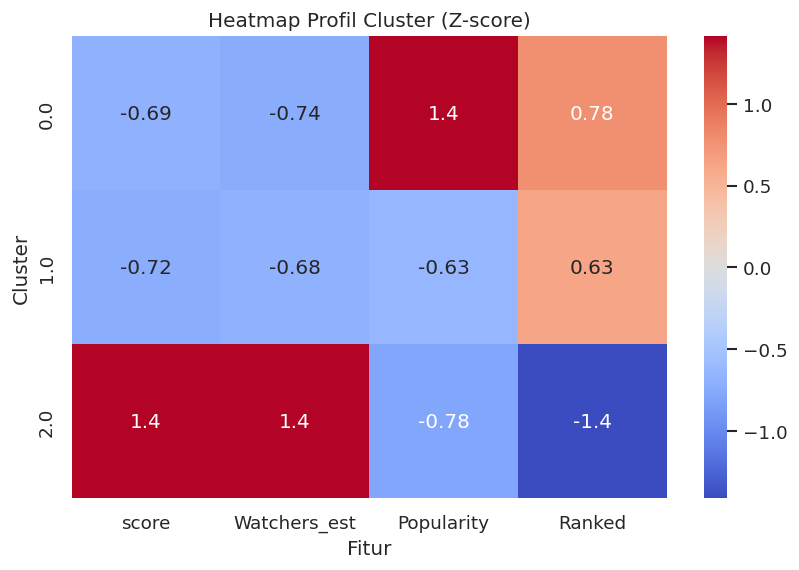

In [35]:
# HEATMAP PROFIL CLUSTER

from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

feature_cols = ['score', 'Watchers_log', 'Popularity', 'Ranked']
df_interpret = df.copy()

df_interpret['Watchers_est'] = np.expm1(df_interpret['Watchers_log']).round().astype(int)

cluster_mean = df_interpret.groupby('cluster')[feature_cols + ['Watchers_est']].mean().round(3)

heatmap_data = cluster_mean[['score', 'Watchers_est', 'Popularity', 'Ranked']].copy()

heatmap_scaled = pd.DataFrame(
    StandardScaler().fit_transform(heatmap_data),
    index=heatmap_data.index,
    columns=heatmap_data.columns
)

plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_scaled, annot=True, cmap='coolwarm', center=0)
plt.title('Heatmap Profil Cluster (Z-score)')
plt.xlabel('Fitur')
plt.ylabel('Cluster')
plt.show()

In [36]:
for c in sorted(df['cluster'].unique()):
    print(f"\nCluster {int(c)}")
    print(df[df['cluster'] == c][['drama_name','score','Watchers','Popularity','Ranked']].sample(5))


Cluster 0
                                        drama_name  score  Watchers  \
783                                       Only You    5.0        12   
365                                Goodbye My Love    7.1       204   
1226                       When Women Powder Twice    7.0        97   
1017  The Clinic for Married Couples: Love and War    9.7        51   
282                           Everybody Say Kimchi    6.6       236   

      Popularity  Ranked  
783        99999   99999  
365        99999   73810  
1226       99999   75754  
1017       99999   99999  
282        99999   79140  

Cluster 1
                drama_name  score  Watchers  Popularity  Ranked
272    Enchanting Neighbor    7.5       453        9627   67468
1146  Thrice Married Woman    6.5      1112        5753   79924
135              Bodyguard    6.9       721        7448   76460
707          My First Time    7.4       549        8655   69256
1038    The Great Merchant    7.5       710        7514   68638

Clus

In [37]:
df_scaled_named = pd.DataFrame(X_scaled, columns=['score','Watchers_log','Popularity','Ranked'], index=df.index)
df_scaled_named['drama_name'] = df['drama_name']
df_scaled_named['cluster'] = labels

for c in sorted(df_scaled_named['cluster'].unique()):
    print(f"\nCluster {int(c)}")
    print(df_scaled_named[df_scaled_named['cluster'] == c][['drama_name','score','Watchers_log','Popularity','Ranked']].sample(5))


Cluster 0
                   drama_name     score  Watchers_log  Popularity    Ranked
530              Land of Wine -1.839960     -1.634839    3.466691  1.960532
513                     Sunok -1.505102     -2.609424    3.466691  1.910105
497                      Jump  3.852619     -2.623824    3.466691  2.638178
529  Lady Cha Dal-rae's Lover -1.170245     -1.598675    3.466691  1.827669
646                      Mina -0.500530     -2.025745    3.466691  1.630491

Cluster 1
                       drama_name     score  Watchers_log  Popularity  \
871                     Ruby Ring -0.667958     -1.099970   -0.076277   
465   Immortal Admiral Yi Sun-sin  0.336614     -1.367481    0.019398   
680               Mother's Garden -1.002816     -1.024727   -0.099175   
1210      Welcome Rain to My Life -0.333101     -1.499132    0.072209   
107        Behind the White Tower  0.169185     -0.942243   -0.122805   

        Ranked  
871   1.725469  
465   1.430294  
680   1.778883  
1210  1.570511 

In [38]:
for c in sorted(df['cluster'].unique()):
    print(f"\nCluster {int(c)}")
    print(df[df['cluster']==c][['drama_name','score','Watchers','Popularity','Ranked']].sample(5).to_string())


Cluster 0
               drama_name  score  Watchers  Popularity  Ranked
665      Mom's Dead Upset    7.3       193       99999   72049
41        Age of Warriors    7.3       103       99999   70995
6            5th Republic    6.9        81       99999   76723
1069       The Last Match    7.5       190       99999   67985
1000  Tears of the Dragon    9.0       119       99999   99999

Cluster 1
                     drama_name  score  Watchers  Popularity  Ranked
995                  Tasty Life    7.1       394       10360   74872
1079  The Merchant: Gaekju 2015    7.1      1561        4586   73788
504            A Sea of Her Own    6.9       256       12811   76938
1230    While You Were Sleeping    7.7      1438        4864   65177
1273       Your Neighbor's Wife    7.3       454        9624   70712

Cluster 2
      drama_name  score  Watchers  Popularity  Ranked
177   Choco Bank    7.1      9189        1108    5482
750  Night Light    7.1      4052        2325    5488
561      Live